Monte Carlo Asian Option Pricing
Project Overview

This project estimates the theoretical price of an arithmetic-average Asian call option using Monte Carlo simulation and Geometric Brownian Motion (GBM).

The model simulates possible future stock-price paths under risk-neutral assumptions, calculates the payoff for each path, and discounts the average payoff to estimate the option's present value.

Objectives
1. Simulate stock-price paths using GBM.
2. Estimate Asian call option premiums using Monte Carlo simulation.
3. Evaluate pricing uncertainty using confidence intervals.
4. Analyze how volatility affects option prices.
5. Visualize simulated stock paths and payoff distributions.
Tools: Python, NumPy, pandas, Matplotlib, SciPy, and yfinance.

In [1]:

# Install the market data library
!pip -q install yfinance

# Numerical calculations
import numpy as np

# Financial data manipulation
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# Historical market data
import yfinance as yf

# File management
import os

# Reproducible random number generation
rng = np.random.default_rng(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
# Calling the S&P 500
#data = yf.download("^GSPC", start="2024-01-01", end="2025-01-01")
#data.to_csv("sp500_2024_data.csv")

In [2]:

# Simulate one stock-price path using Geometric Brownian Motion

def gbm_path(S0, r, sigma, T, n):

    # Length of each time step
    dt = T / n

    # Start with the initial stock price
    prices = [S0]

    # Generate n future stock prices
    for i in range(n):

        # Random market shock
        Z = rng.normal(0, 1)

        # Calculate the next stock price
        new_price = prices[-1] * np.exp(
            (r - 0.5 * sigma**2) * dt
            + sigma * np.sqrt(dt) * Z
        )

        # Save the new price
        prices.append(new_price)

    return np.array(prices)




Starting price: 500.0
Ending price: 541.95
Number of prices: 253
All prices positive: True


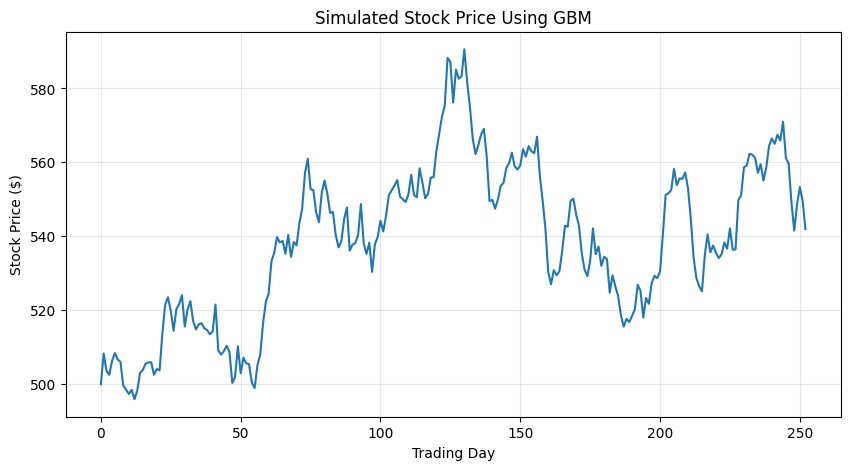

In [4]:

# Test the upgraded GBM function

S0 = 500
r = 0.0383
sigma = 0.15
T = 1
n = 252

test_path = gbm_path(S0, r, sigma, T, n)

print("Starting price:", test_path[0])
print("Ending price:", round(test_path[-1], 2))
print("Number of prices:", len(test_path))
print("All prices positive:", np.all(test_path > 0))

plt.figure(figsize=(10, 5))
plt.plot(test_path)
plt.title("Simulated Stock Price Using GBM")
plt.xlabel("Trading Day")
plt.ylabel("Stock Price ($)")
plt.grid(alpha=0.3)
plt.show()


In [5]:

def asian_call_premium(S0, K, r, sigma, T, n, n_paths):

    payoffs = []

    # Generate many possible stock-price paths
    for i in range(n_paths):

        path = gbm_path(S0, r, sigma, T, n)

        # Calculate average stock price
        average_price = np.mean(path)

        # Calculate Asian call payoff
        payoff = max(average_price - K, 0)

        payoffs.append(payoff)

    # Convert payoffs to NumPy array
    payoffs = np.array(payoffs)

    # Discount future payoffs to today's value
    discounted_payoffs = np.exp(-r * T) * payoffs

    # Estimate the theoretical option premium
    premium = np.mean(discounted_payoffs)

    # Calculate standard error
    standard_error = (
        np.std(discounted_payoffs, ddof=1)
        / np.sqrt(n_paths)
    )

    # Calculate approximate 95% confidence interval
    ci_lower = premium - 1.96 * standard_error
    ci_upper = premium + 1.96 * standard_error

    return premium, standard_error, ci_lower, ci_upper



In [6]:

# Asian call option parameters

S0 = 500
K = 510
r = 0.0383
sigma = 0.15
T = 1
n = 252

# Number of Monte Carlo simulations
n_paths = 10000

# Run the pricing model
premium, se, ci_lower, ci_upper = asian_call_premium(
    S0, K, r, sigma, T, n, n_paths
)

print("Monte Carlo Asian Call Option Pricing")
print("-------------------------------------")
print(f"Estimated Premium: ${premium:.2f}")
print(f"Standard Error: ${se:.4f}")
print(f"95% Confidence Interval: (${ci_lower:.2f}, ${ci_upper:.2f})")


Monte Carlo Asian Call Option Pricing
-------------------------------------
Estimated Premium: $16.99
Standard Error: $0.2665
95% Confidence Interval: ($16.46, $17.51)


In [7]:

# Compare Monte Carlo results at different simulation sizes

simulation_sizes = [100, 500, 1000, 5000, 10000]

results = []

for size in simulation_sizes:

    premium, se, lower, upper = asian_call_premium(
        S0, K, r, sigma, T, n, size
    )

    results.append({
        "Simulations": size,
        "Premium": premium,
        "Standard Error": se,
        "CI Lower": lower,
        "CI Upper": upper
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))


   Simulations  Premium  Standard Error  CI Lower  CI Upper
0          100  14.6884          2.3896   10.0049   19.3719
1          500  16.2960          1.1050   14.1301   18.4618
2         1000  18.0748          0.8790   16.3519   19.7976
3         5000  17.4110          0.3746   16.6768   18.1451
4        10000  16.9828          0.2652   16.4631   17.5025


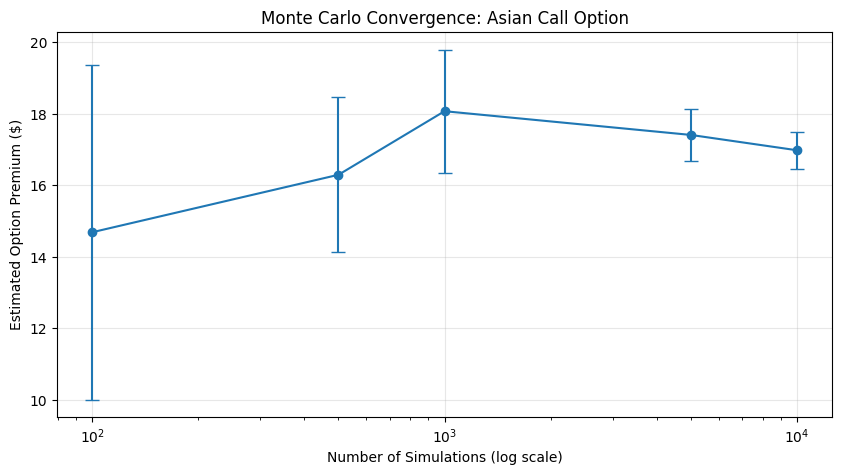

In [8]:

plt.figure(figsize=(10, 5))

plt.errorbar(
    results_df["Simulations"],
    results_df["Premium"],
    yerr=1.96 * results_df["Standard Error"],
    fmt="o-",
    capsize=5
)

plt.xscale("log")

plt.title("Monte Carlo Convergence: Asian Call Option")
plt.xlabel("Number of Simulations (log scale)")
plt.ylabel("Estimated Option Premium ($)")
plt.grid(alpha=0.3)

plt.show()


In [9]:

# Volatility sensitivity analysis

volatility_levels = [0.10, 0.15, 0.20, 0.25, 0.30]

volatility_results = []

for vol in volatility_levels:

    # Reset the random generator for fair comparison
    rng = np.random.default_rng(42)

    premium, se, lower, upper = asian_call_premium(
        S0=500,
        K=510,
        r=0.0383,
        sigma=vol,
        T=1,
        n=252,
        n_paths=10000
    )

    volatility_results.append({
        "Volatility": vol,
        "Premium": premium,
        "Standard Error": se,
        "CI Lower": lower,
        "CI Upper": upper
    })

volatility_df = pd.DataFrame(volatility_results)

print(volatility_df.round(4))


   Volatility  Premium  Standard Error  CI Lower  CI Upper
0        0.10  11.2757          0.1736   10.9355   11.6159
1        0.15  16.9882          0.2665   16.4658   17.5105
2        0.20  22.6999          0.3634   21.9876   23.4122
3        0.25  28.4086          0.4645   27.4982   29.3190
4        0.30  34.1124          0.5700   32.9953   35.2295


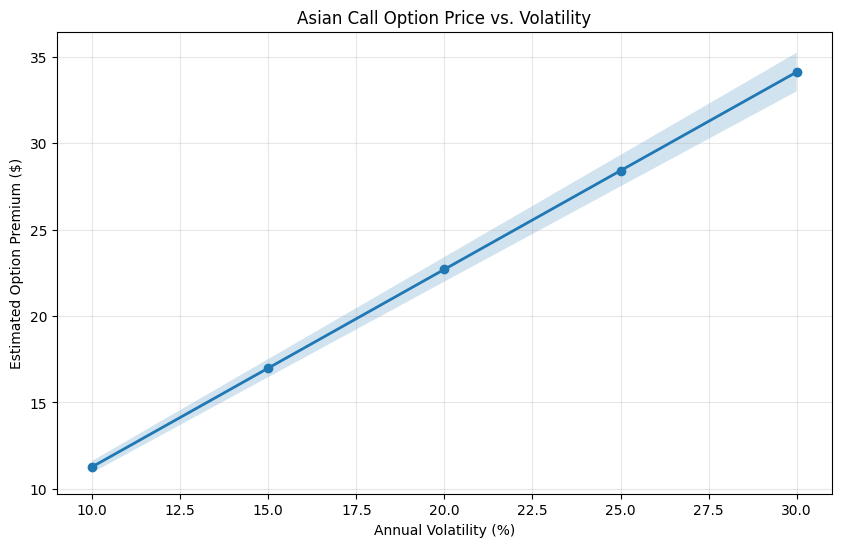

In [10]:

plt.figure(figsize=(10, 6))

plt.plot(
    volatility_df["Volatility"] * 100,
    volatility_df["Premium"],
    marker="o",
    linewidth=2
)

plt.fill_between(
    volatility_df["Volatility"] * 100,
    volatility_df["CI Lower"],
    volatility_df["CI Upper"],
    alpha=0.2
)

plt.title("Asian Call Option Price vs. Volatility")
plt.xlabel("Annual Volatility (%)")
plt.ylabel("Estimated Option Premium ($)")
plt.grid(alpha=0.3)

plt.show()


### Volatility Sensitivity Analysis — Results and Discussion

To investigate the relationship between volatility and Asian option valuation, I conducted a Monte Carlo sensitivity analysis using 10,000 simulated stock-price paths for each volatility level.

Annual volatility was varied from 10% to 30%, while the initial stock price ($500), strike price ($510), risk-free rate (3.83%), and time to maturity (one year) were held constant.

**Key findings:**

1. **Option premiums increased with volatility.** The estimated premium rose from $11.28 at 10% volatility to $34.11 at 30% volatility, representing an increase of approximately 202.5%.

2. **The relationship was approximately linear across the tested range.** Each five-percentage-point increase in annual volatility increased the estimated option premium by approximately $5.71.

3. **Simulation uncertainty increased at higher volatility levels.** The standard error rose from $0.1736 to $0.5700, reflecting greater variability in simulated discounted payoffs.

These findings are consistent with the theoretical behavior of fixed-strike Asian call options under the assumed GBM framework. Greater volatility increases the potential for higher average stock prices, while option payoffs remain bounded below by zero.

**Limitations:** The results depend on the assumed GBM dynamics, constant volatility, risk-free rate, and averaging convention. The analysis demonstrates theoretical pricing sensitivity rather than forecasting actual market option prices.

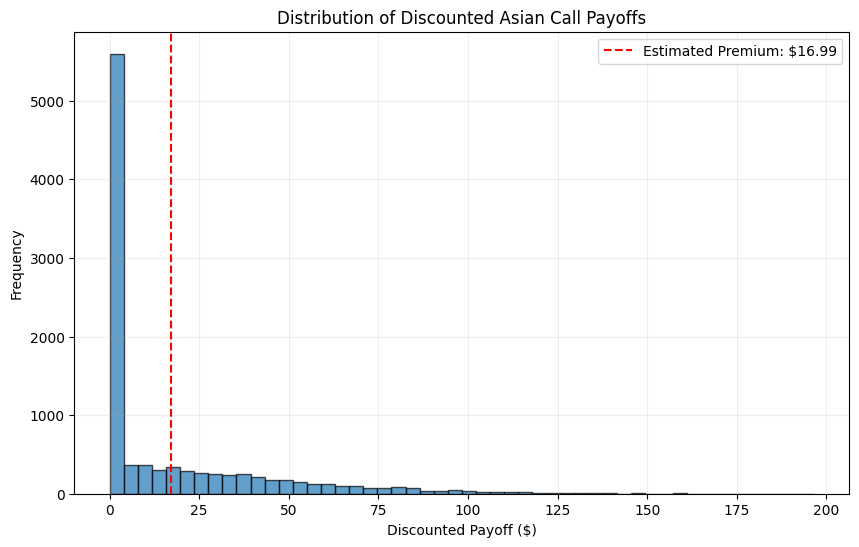

Average discounted payoff: $16.99
Probability of zero payoff: 52.25%


In [11]:

# Generate discounted Asian call payoffs

rng = np.random.default_rng(42)

payoffs = []

for i in range(10000):

    path = gbm_path(S0, r, sigma, T, n)

    average_price = np.mean(path)

    payoff = max(average_price - K, 0)

    discounted_payoff = np.exp(-r * T) * payoff

    payoffs.append(discounted_payoff)

payoffs = np.array(payoffs)

# Visualize the distribution
plt.figure(figsize=(10, 6))

plt.hist(payoffs, bins=50, edgecolor="black", alpha=0.7)

plt.axvline(
    np.mean(payoffs),
    color="red",
    linestyle="--",
    label=f"Estimated Premium: ${np.mean(payoffs):.2f}"
)

plt.title("Distribution of Discounted Asian Call Payoffs")
plt.xlabel("Discounted Payoff ($)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

print(f"Average discounted payoff: ${np.mean(payoffs):.2f}")
print(f"Probability of zero payoff: {np.mean(payoffs == 0):.2%}")


### Payoff Distribution Analysis

Using 10,000 Monte Carlo simulations, the model estimated an arithmetic-average Asian call option premium of $16.99.

Approximately 52.25% of simulated paths resulted in zero payoff, indicating that the average stock price did not exceed the $510 strike price.

The remaining 47.75% of simulations generated positive payoffs. The distribution illustrates the asymmetric payoff structure of a call option: payoffs are bounded below by zero, while sufficiently high average stock prices generate increasingly large payoffs.

Despite more than half of simulated paths producing zero payoff, the option retained a positive theoretical value because the discounted positive payoffs contributed to its expected value.

These probabilities are calculated under risk-neutral GBM assumptions and should not be interpreted as predictions of real-world investment outcomes.

In [12]:
# Model validation: zero volatility

rng = np.random.default_rng(42)

premium, se, lower, upper = asian_call_premium(
    S0=500,
    K=510,
    r=0.0383,
    sigma=0.0,
    T=1,
    n=252,
    n_paths=1000
)

print(f"Option Premium: ${premium:.4f}")
print(f"Standard Error: ${se:.6f}")
print(f"95% CI: (${lower:.4f}, ${upper:.4f})")


Option Premium: $0.0000
Standard Error: $0.000000
95% CI: ($0.0000, $0.0000)


In [13]:

# Validation: Compare Monte Carlo against
# the deterministic zero-volatility benchmark

times = np.linspace(0, T, n + 1)

# Exact stock-price path when volatility is zero
deterministic_path = S0 * np.exp(r * times)

# Same averaging convention as our Monte Carlo model
average_price = np.mean(deterministic_path)

# Exact discounted Asian call payoff
expected_premium = np.exp(-r * T) * max(
    average_price - K, 0
)

# Monte Carlo estimate with zero volatility
rng = np.random.default_rng(42)

mc_premium, se, lower, upper = asian_call_premium(
    S0, K, r, 0.0, T, n, 1000
)

print(f"Average Stock Price: ${average_price:.4f}")
print(f"Exact Benchmark Premium: ${expected_premium:.4f}")
print(f"Monte Carlo Premium: ${mc_premium:.4f}")
print(f"Absolute Error: ${abs(mc_premium - expected_premium):.6f}")

assert np.isclose(mc_premium, expected_premium)
print("Validation Test: PASSED")


Average Stock Price: $509.6987
Exact Benchmark Premium: $0.0000
Monte Carlo Premium: $0.0000
Absolute Error: $0.000000
Validation Test: PASSED


In [14]:

# Validation: Strike price and nonnegative premiums

strike_prices = [490, 500, 510, 520, 550]
premiums = []

for strike in strike_prices:

    # Use identical random shocks for each strike
    rng = np.random.default_rng(42)

    premium, se, lower, upper = asian_call_premium(
        S0=500,
        K=strike,
        r=0.0383,
        sigma=0.15,
        T=1,
        n=252,
        n_paths=10000
    )

    premiums.append(premium)

    print(f"Strike ${strike}: Premium ${premium:.4f}")

# Test 1: All option premiums must be nonnegative
assert all(p >= 0 for p in premiums)
print("Nonnegative Premium Test: PASSED")

# Test 2: Premiums must decrease or stay equal
# as the strike price increases
assert all(
    premiums[i] >= premiums[i + 1]
    for i in range(len(premiums) - 1)
)
print("Strike Monotonicity Test: PASSED")


Strike $490: Premium $27.8919
Strike $500: Premium $22.0136
Strike $510: Premium $16.9882
Strike $520: Premium $12.8258
Strike $550: Premium $4.8577
Nonnegative Premium Test: PASSED
Strike Monotonicity Test: PASSED


In [15]:

# Validation: Positive-payoff deterministic benchmark

test_K = 490

times = np.linspace(0, T, n + 1)
deterministic_path = S0 * np.exp(r * times)

average_price = np.mean(deterministic_path)

exact_premium = np.exp(-r * T) * max(
    average_price - test_K, 0
)

rng = np.random.default_rng(42)

mc_premium, se, lower, upper = asian_call_premium(
    S0=500,
    K=test_K,
    r=0.0383,
    sigma=0.0,
    T=1,
    n=252,
    n_paths=1000
)

print(f"Exact Premium: ${exact_premium:.4f}")
print(f"Monte Carlo Premium: ${mc_premium:.4f}")
print(f"Absolute Error: ${abs(mc_premium - exact_premium):.6f}")

assert exact_premium > 0
assert np.isclose(mc_premium, exact_premium)

print("Positive-Payoff Validation: PASSED")


Exact Premium: $18.9585
Monte Carlo Premium: $18.9585
Absolute Error: $0.000000
Positive-Payoff Validation: PASSED
